# Dogecoin Price Prediction with Machine Learning

Dogecoin, bitcoin fiyatlarındaki son düşüşün sebebidir. Dogecoin'in fiyatı şu anda bitcoin'e kıyasla çok ucuz, ancak Tesla'nın CEO'su Elon Musk da dahil olmak üzere bazı finans uzmanları, Dogecoin'in fiyatında yakında bir artış göreceğimizi iddia ediyor. Dolayısıyla, Dogecoin'in gelecekteki fiyatlarını nasıl tahmin edeceğinizi öğreneceğiz.

Dogecoin Fiyat Tahmini

Bir kripto paranın fiyatını tahmin etmek makine öğreniminde bir regresyon problemidir. Bitcoin, kripto paranın en başarılı örneklerinden biridir, ancak yakın zamanda dogecoin nedeniyle bitcoin fiyatlarında büyük bir düşüş gördük. Bitcoin'in aksine, dogecoin şu anda çok ucuz, ancak finans uzmanları dogecoin fiyatlarında büyük bir artış görebileceğimizi öngörüyor.

Dogecoin fiyat tahmini görevi için kullanabileceğimiz birçok makine öğrenimi yaklaşımı vardır. Bir makine öğrenimi modeli eğitebilir veya Facebook Prophet Modeli gibi halihazırda mevcut güçlü bir modeli de kullanabilirsiniz. Ancak aşağıdaki bölümde, makine öğrenimiyle Dogecoin fiyat tahmini görevi için Python'daki autots kütüphanesini kullanacağım.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from seaborn import regression
data = pd.read_csv("Dogecoin.csv")
print(data.head())

         Date      Open      High       Low     Close  Adj Close     Volume
0  2017-08-24  0.001731  0.001845  0.001722  0.001816   0.001816  4796720.0
1  2017-08-25  0.001808  0.001830  0.001762  0.001790   0.001790  2654040.0
2  2017-08-26  0.001787  0.001797  0.001735  0.001778   0.001778  1935350.0
3  2017-08-27  0.001779  0.001784  0.001745  0.001760   0.001760  2241620.0
4  2017-08-28  0.001764  0.001825  0.001751  0.001825   0.001825  3210440.0


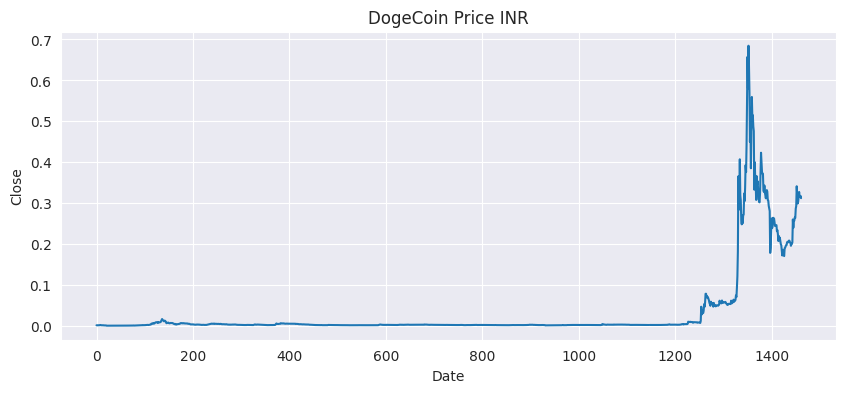

In [2]:
#Bu veri setinde, "kapanış" sütunu, gelecekteki değerlerini tahmin etmek istediğimiz değerleri içerir, bu nedenle Dogecoin'in kapanış fiyatlarının geçmiş değerlerine daha yakından bakalım

data.dropna()
plt.figure(figsize=(10, 4))
plt.title("DogeCoin Price INR")
plt.xlabel("Date")
plt.ylabel("Close")
plt.plot(data["Close"])
plt.show()

In [3]:
#pip install autots

In [4]:
#Şimdi Dogecoin'in gelecekteki fiyatlarını tahmin etmek için bir makine öğrenme modeli eğitmek amacıyla Python'daki autots kütüphanesini kullanacağım. Eğer bu kütüphaneyi daha önce hiç kullanmadıysanız pip komutunu kullanarak sisteminize kolayca kurabilirsiniz.

from autots import AutoTS
model = AutoTS(forecast_length=10, frequency='infer', ensemble='simple', drop_data_older_than_periods=200)
model = model.fit(data, date_col='Date', value_col='Close', id_col=None)

prediction = model.predict()
forecast = prediction.forecast
print("DogeCoin Price Prediction")
print(forecast)

Using 2 cpus for n_jobs.
Data frequency is: D, used frequency is: D
Old data dropped by `drop_data_older_than_periods`.
Model Number: 1 with model ARIMA in generation 0 of 20


 This problem is unconstrained.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =           17     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f= -2.01235D+00    |proj g|=  7.43644D+00

At iterate    1    f= -2.03481D+00    |proj g|=  7.27684D-01

At iterate    2    f= -2.03491D+00    |proj g|=  3.71053D-01

At iterate    3    f= -2.03495D+00    |proj g|=  4.82530D-02

At iterate    4    f= -2.03497D+00    |proj g|=  7.94744D-02

At iterate    5    f= -2.03523D+00    |proj g|=  5.96901D-01

At iterate    6    f= -2.03571D+00    |proj g|=  1.14818D+00

At iterate    7    f= -2.03673D+00    |proj g|=  1.72769D+00

At iterate    8    f= -2.03804D+00    |proj g|=  1.77947D+00

At iterate    9    f= -2.03949D+00    |proj g|=  9.30809D-01

At iterate   10    f= -2.04006D+00    |proj g|=  2.32954D-01

At iterate   11    f= -2.04017D+00    |proj g|=  4.59827D-01

At iterate   12    f= -2.04032D+00    |proj g|=  6.24373D-01

At iterate   13    f= -2.0


   evaluations in the last line search.  Termination
   may possibly be caused by a bad search direction.



At iterate   86    f= -2.05199D+00    |proj g|=  4.23501D-03

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
   17     86    124      1     0     0   4.235D-03  -2.052D+00
  F =  -2.0519895805952610     

CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH             
Model Number: 2 with model AverageValueNaive in generation 0 of 20
Model Number: 3 with model AverageValueNaive in generation 0 of 20
Model Number: 4 with model AverageValueNaive in generation 0 of 20
Model Number: 5 with model DatepartRegression in generation 0 of 20
Model Number: 6 with model DatepartRegression in generation 0 of 20
Model Number: 7 with mod

...

/home/sifa/projects/first/pythonProject/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/sifa/projects/first/pythonProject/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


314 - MultivariateRegression with avg smape 4.86: 
Model Number: 315 of 317 with model Cassandra for Validation 3
315 - Cassandra with avg smape 36.69: 
Model Number: 316 of 317 with model MetricMotif for Validation 3
316 - MetricMotif with avg smape 37.42: 
Model Number: 317 of 317 with model MetricMotif for Validation 3
317 - MetricMotif with avg smape 185.2: 
Model Number: 3182 with model Ensemble in generation 22 of Ensembles
Model Number: 3183 with model Ensemble in generation 22 of Ensembles


/home/sifa/projects/first/pythonProject/.venv/lib/python3.12/site-packages/autots/evaluator/auto_model.py:2462: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  validation_results.model_results = validation_results.model_results.replace(


Model Number: 3184 with model Ensemble in generation 22 of Ensembles
Model Number: 3185 with model Ensemble in generation 22 of Ensembles
Model Number: 3186 with model Ensemble in generation 22 of Ensembles
Model Number: 3187 with model Ensemble in generation 22 of Ensembles
Model Number: 3188 with model Ensemble in generation 22 of Ensembles
Model Number: 3189 with model Ensemble in generation 22 of Ensembles
Validation Round: 1
Model Number: 1 of 8 with model Ensemble for Validation 1
📈 1 - Ensemble with avg smape 13.51: 
Model Number: 2 of 8 with model Ensemble for Validation 1
2 - Ensemble with avg smape 18.14: 
Model Number: 3 of 8 with model Ensemble for Validation 1
3 - Ensemble with avg smape 21.21: 
Model Number: 4 of 8 with model Ensemble for Validation 1
4 - Ensemble with avg smape 24.05: 
Model Number: 5 of 8 with model Ensemble for Validation 1
5 - Ensemble with avg smape 16.8: 
Model Number: 6 of 8 with model Ensemble for Validation 1
6 - Ensemble with avg smape 20.04: 
M

/home/sifa/projects/first/pythonProject/.venv/lib/python3.12/site-packages/autots/evaluator/auto_model.py:2462: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  validation_results.model_results = validation_results.model_results.replace(
/home/sifa/projects/first/pythonProject/.venv/lib/python3.12/site-packages/autots/evaluator/auto_model.py:2462: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  validation_results.model_results = validation_results.model_results.replace(


In [6]:
import joblib
joblib.dump(model, 'autots_model.pkl')

['autots_model.pkl']

Böylelikle verilen datada geleceğe dair Dogecoin için tahminde bulunduk.